## Intent Classification & Optimization

**Project:** Banking Conversational AI Analytics  
**Notebook 02:** Baseline modeling, targeted intent optimization, confidence-based routing, calibration, and hold-out evaluation  
**Language:** Python / scikit-learn

## Objective

Build an interpretable **77-class banking intent classifier** and evaluate whether its predictions could support a virtual assistant's intent-routing decisions. Compare feature representations, examine critical-intent errors, and quantify the trade-off between automatic classification coverage and accuracy.


### Workflow

1. Prepare a clean training set and a stratified validation split.
2. Establish a word TF-IDF + Logistic Regression baseline.
3. Analyze misclassifications, especially card-related intents.
4. Test class weighting, character n-grams, and hybrid features.
5. Analyze confidence scores, selective classification, and calibration.
6. Audit train/test overlaps and evaluate the selected model on a hold-out test set.

**Expected files:** `data/raw/train.csv`, `data/raw/test.csv`, and this notebook in `notebooks/`.

## 1. Setup, Data Quality & Validation Split

### 1.1 Imports and display settings

Use one import cell to keep the notebook readable. Showing full text is important because truncated utterances can hide the actual reason for an intent misclassification.

In [63]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import FeatureUnion, Pipeline

pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 1000)


def normalize_text(text_series):
    """Normalize text for duplicate/overlap checks, not model features."""
    return (
        text_series.str.casefold()
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )


### 1.2 Load the dataset and check duplicate labels

**Why:** Exact textual duplicates can appear in slightly different formats (case or whitespace). Conflicting labels for the same normalized utterance must be investigated rather than silently removed. The classification model itself will still receive the **original, unnormalized** `text` values.

The path resolver supports both common VS Code/Jupyter working directories: the project root and the `notebooks/` folder.

In [64]:
# Resolve data paths without assuming a fixed Jupyter working directory.
candidate_directories = [Path("../data/raw"), Path("data/raw")]
data_dir = next(
    (
        directory
        for directory in candidate_directories
        if (directory / "train.csv").exists()
        and (directory / "test.csv").exists()
    ),
    None,
)
if data_dir is None:
    raise FileNotFoundError(
        "Cannot find data/raw/train.csv and data/raw/test.csv. "
        "Open the project root or notebooks/ as the working directory."
    )

train = pd.read_csv(data_dir / "train.csv")
train["normalized_text"] = normalize_text(train["text"])

# Check whether a normalized utterance maps to different intent labels.
label_counts = train.groupby("normalized_text")["category"].nunique()
conflicts = label_counts[label_counts > 1]
print("Conflicting labels:", len(conflicts))

if not conflicts.empty:
    display(train[train["normalized_text"].isin(conflicts.index)])
    raise ValueError("Review conflicting labels before training.")

# Keep one instance of each normalized utterance after checking labels.
train_clean = train.drop_duplicates(subset="normalized_text").copy()
print("Original:", len(train))
print("Cleaned:", len(train_clean))


Conflicting labels: 0
Original: 10003
Cleaned: 9999


**Observed data-quality check:** The original run found **10,003** training rows, **4** normalized-text duplicates (with no label conflicts), and **9,999** remaining rows. Deduplication is applied *before* the train/validation split to avoid directly repeated utterances in both subsets.

### 1.3 Stratified train/validation split

**Why:** Reserve 20% of cleaned training data for model development and comparison. `stratify=y` approximately preserves the frequency of each of the 77 intent classes. The published `test.csv` is **not used** for model selection or threshold tuning.

In [65]:
X = train_clean["text"]
y = train_clean["category"]

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))


Training samples: 7999
Validation samples: 2000


## 2. Baseline: Word TF-IDF + Logistic Regression

**Hypothesis:** Word unigrams and bigrams can establish a useful, inexpensive and interpretable baseline for banking intent classification.

- `TfidfVectorizer(ngram_range=(1, 2))`: represents individual words and consecutive word pairs.
- `min_df=2`: excludes features occurring in only one training document.
- `LogisticRegression`: predicts one of 77 intent classes.
- `Pipeline`: ensures that TF-IDF learns its vocabulary from the training subset only.

In [66]:
baseline_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
    )),
])


In [67]:
# Fit only on the training subset; validation is used for evaluation.
baseline_model.fit(X_train, y_train)
val_pred_baseline = baseline_model.predict(X_val)


### 2.1 Overall and per-intent metrics

**Accuracy** treats each validation message equally; **Macro F1** treats each intent class equally. Macro F1 is especially informative because the training class sizes differ. A single overall score cannot reveal problematic banking intents.

In [68]:
baseline_accuracy = accuracy_score(y_val, val_pred_baseline)
baseline_macro_f1 = f1_score(y_val, val_pred_baseline, average="macro")

print(f"Accuracy: {baseline_accuracy:.4f}")
print(f"Macro F1: {baseline_macro_f1:.4f}")


Accuracy: 0.8445
Macro F1: 0.8423


In [69]:
report_baseline_df = pd.DataFrame(
    classification_report(
        y_val,
        val_pred_baseline,
        output_dict=True,
        zero_division=0,
    )
).T

# Investigate the ten lowest-performing intent classes.
display(
    report_baseline_df.loc[train_clean["category"].unique()]
    .sort_values("f1-score")
    .head(10)
)


,precision,recall,f1-score,support
card_acceptance,0.636364,0.583333,0.608696,12.0
virtual_card_not_working,1.000000,0.500000,0.666667,8.0
lost_or_stolen_card,0.733333,0.687500,0.709677,16.0
top_up_failed,0.791667,0.655172,0.716981,29.0
order_physical_card,0.739130,0.708333,0.723404,24.0
transfer_not_received_by_recipient,0.714286,0.735294,0.724638,34.0
topping_up_by_card,1.000000,0.571429,0.727273,21.0
supported_cards_and_currencies,0.700000,0.807692,0.750000,26.0
card_not_working,0.739130,0.772727,0.755556,22.0
declined_cash_withdrawal,0.717949,0.800000,0.756757,35.0


### 2.2 Confusion matrix and intent-level errors

The **rows** of a confusion matrix are actual labels and the **columns** are predicted labels. Off-diagonal entries reveal which intents the model confuses. With 77 classes, targeted tables are more informative than a crowded full heatmap.

In [70]:
intent_labels = sorted(y_val.unique())

cm_baseline = confusion_matrix(
    y_val,
    val_pred_baseline,
    labels=intent_labels,
)

cm_baseline_df = pd.DataFrame(
    cm_baseline,
    index=intent_labels,
    columns=intent_labels,
)


In [71]:
weak_intents = [
    "card_acceptance",
    "virtual_card_not_working",
    "lost_or_stolen_card",
]

for intent in weak_intents:
    print(f"\nActual intent: {intent}")
    mistakes = (
        cm_baseline_df.loc[intent]
        .drop(intent)
        .sort_values(ascending=False)
    )
    # Display only observed misclassifications (ignore zero-count categories).
    display(mistakes[mistakes > 0].head(5))



Actual intent: card_acceptance


atm_support         2
card_not_working    2
card_arrival        1
Name: card_acceptance, dtype: int64


Actual intent: virtual_card_not_working


getting_virtual_card           2
get_disposable_virtual_card    1
disposable_card_limits         1
Name: virtual_card_not_working, dtype: int64


Actual intent: lost_or_stolen_card


cash_withdrawal_not_recognised    1
card_arrival                      1
compromised_card                  1
card_delivery_estimate            1
card_about_to_expire              1
Name: lost_or_stolen_card, dtype: int64

### 2.3 Inspect concrete examples, not only summary metrics

Understanding the wording behind wrong classifications is essential. **False negatives** for `lost_or_stolen_card` are real requests missed by the model; **false positives** are different intents incorrectly routed to that category. Sensitive intents need separate consideration from aggregate accuracy.

In [72]:
validation_results = pd.DataFrame({
    "text": X_val.to_numpy(),
    "actual_intent": y_val.to_numpy(),
    "predicted_intent": val_pred_baseline,
})

baseline_errors = validation_results[
    validation_results["actual_intent"] != validation_results["predicted_intent"]
].copy()

print("Total misclassifications:", len(baseline_errors))


Total misclassifications: 311


In [73]:
# False negatives: actual lost/stolen card requests classified elsewhere.
intent = "lost_or_stolen_card"

display(
    baseline_errors.loc[
        baseline_errors["actual_intent"] == intent,
        ["text", "actual_intent", "predicted_intent"],
    ]
)


,text,actual_intent,predicted_intent
987,Can you provide information for freezing my card immediately?,lost_or_stolen_card,card_delivery_estimate
1043,I need to order a new card as my other one was stolen.,lost_or_stolen_card,card_about_to_expire
1306,Is there any way for you to find my card?,lost_or_stolen_card,card_arrival
1544,"I thought I left my card at a restaurant, but they claim not to have it and now I don't have any idea where it is. I'm so worried that someone might be using it fraudulently. Is there any way to look into this?",lost_or_stolen_card,compromised_card
1837,Could you please freeze my card immediately?,lost_or_stolen_card,cash_withdrawal_not_recognised


In [74]:
# False positives: another intent mistakenly predicted as lost/stolen card.
false_positives = validation_results.loc[
    (validation_results["predicted_intent"] == "lost_or_stolen_card")
    & (validation_results["actual_intent"] != "lost_or_stolen_card")
].copy()

display(false_positives)


,text,actual_intent,predicted_intent
361,My card was stolen and used to make several purchases. Please freeze my card so no one can use it.,compromised_card,lost_or_stolen_card
419,Can you tell me what i steps i should take since my card was stolen?,lost_or_stolen_phone,lost_or_stolen_card
816,My cards were stolen,lost_or_stolen_phone,lost_or_stolen_card
1229,Has my card been lost in delivery?,card_arrival,lost_or_stolen_card


In [75]:
# Check precision/recall trade-off for this safety-sensitive intent.
display(
    report_baseline_df.loc[
        "lost_or_stolen_card",
        ["precision", "recall", "f1-score", "support"],
    ]
)


precision     0.733333
recall        0.687500
f1-score      0.709677
support      16.000000
Name: lost_or_stolen_card, dtype: float64

**Baseline observations (saved run):** Accuracy **0.8445** and Macro F1 **0.8423**, with **311** misclassifications across 2,000 validation messages. `lost_or_stolen_card` has Recall **0.6875** (11/16 correctly recognized). Some messages explicitly mention *stolen* or *freeze*; others are ambiguous. These are **hypotheses about failure mechanisms**, not proof that every error is caused by the classifier rather than the labels.

## 3. Experiment 01 — Class Weight Balancing

**Hypothesis:** Weighting infrequent intent classes more heavily might improve recall for underrepresented intents.

**Controlled change:** Switch only the Logistic Regression `class_weight` setting to `"balanced"`. Leave the split, TF-IDF settings, and all other model parameters unchanged.

In [76]:
balanced_model = clone(baseline_model)
balanced_model.set_params(classifier__class_weight="balanced")

balanced_model.fit(X_train, y_train)
val_pred_balanced = balanced_model.predict(X_val)

print("Baseline Accuracy:", accuracy_score(y_val, val_pred_baseline))
print("Balanced Accuracy:", accuracy_score(y_val, val_pred_balanced))
print("Baseline Macro F1:", f1_score(y_val, val_pred_baseline, average="macro"))
print("Balanced Macro F1:", f1_score(y_val, val_pred_balanced, average="macro"))


Baseline Accuracy: 0.8445
Balanced Accuracy: 0.8475
Baseline Macro F1: 0.8423297590779911
Balanced Macro F1: 0.850906666605079


In [77]:
report_balanced_df = pd.DataFrame(
    classification_report(y_val, val_pred_balanced, output_dict=True, zero_division=0)
).T

lost_card_balancing_comparison = pd.DataFrame({
    "Baseline": report_baseline_df.loc["lost_or_stolen_card"],
    "Balanced": report_balanced_df.loc["lost_or_stolen_card"],
})

display(lost_card_balancing_comparison)


,Baseline,Balanced
precision,0.733333,0.619048
recall,0.687500,0.812500
f1-score,0.709677,0.702703
support,16.000000,16.000000


### 3.1 Investigate possible annotation inconsistencies

The validation examples include some utterances explicitly mentioning a stolen **card** but labeled `lost_or_stolen_phone`. Inspect a small training sample for the latter category to understand its usual labeling intent. Do not relabel a published benchmark based on a few examples; flag them for review.

In [78]:
# Inspect typical utterances for the potentially confusing phone label.
display(
    train.loc[train["category"] == "lost_or_stolen_phone", ["text", "category"]]
    .sample(n=10, random_state=42)
)


,text,category
5295,I lost my phone. What do I need to do?,lost_or_stolen_phone
5298,My phone is missing or stolen.,lost_or_stolen_phone
5255,I think I lost my phone. Is there a way to prevent anyone from getting into my account on it?,lost_or_stolen_phone
5306,my phone has been stolen by someone,lost_or_stolen_phone
5277,Please help! I was mugged and everything stolen. What do I do to stop them from accessing my account?,lost_or_stolen_phone
5315,"Everything I have was stolen yesterday making it so I don't have access to the app, what should I do?",lost_or_stolen_phone
5324,I can't use the app because I got mugged yesterday and they took everything. I need some help.,lost_or_stolen_phone
5261,"Help, my phone was stolen, please advise!",lost_or_stolen_phone
5291,"phone is gone, dont want others to access account information",lost_or_stolen_phone
5359,"My phone is lost I don't want someone to use my account, what can I do?",lost_or_stolen_phone


In [79]:
# Find validation examples where balancing changed the predicted intent.
baseline_balanced_comparison = pd.DataFrame({
    "text": X_val.to_numpy(),
    "actual": y_val.to_numpy(),
    "baseline": val_pred_baseline,
    "balanced": val_pred_balanced,
})

changed_predictions = baseline_balanced_comparison.loc[
    baseline_balanced_comparison["baseline"]
    != baseline_balanced_comparison["balanced"]
]

display(
    changed_predictions.loc[
        (changed_predictions["actual"] == "lost_or_stolen_card")
        | (changed_predictions["baseline"] == "lost_or_stolen_card")
        | (changed_predictions["balanced"] == "lost_or_stolen_card")
    ]
)


,text,actual,baseline,balanced
247,There's a possibility that my card was compromised.,compromised_card,declined_card_payment,lost_or_stolen_card
294,I have left my card at my parents house. Can you send me a spare one please to use in the meantime?,getting_spare_card,card_not_working,lost_or_stolen_card
897,I don't have my card after 1 week. What are my next steps?,card_arrival,card_arrival,lost_or_stolen_card
1306,Is there any way for you to find my card?,lost_or_stolen_card,card_arrival,lost_or_stolen_card
1837,Could you please freeze my card immediately?,lost_or_stolen_card,cash_withdrawal_not_recognised,lost_or_stolen_card
1939,If my card was lost or stolen can I re-link it?,card_linking,card_linking,lost_or_stolen_card


### 3.2 Findings — Class balancing

- Validation Macro F1 improved from **0.8423** to **0.8509**.
- `lost_or_stolen_card` Recall improved from **0.6875** to **0.8125** (11/16 → 13/16).
- Its Precision decreased from **0.7333** to **0.6190**, as false positives rose from 4 to 8.
- The selected intent's F1 **decreased slightly**, even though overall Macro F1 increased.

**Decision:** Keep the balanced model as a comparison candidate; do not conclude that higher recall necessarily means a better operational system.

## 4. Experiment 02 — Character N-gram TF-IDF

**Hypothesis:** Character n-grams may better capture spelling variation and fragments within words, potentially improving intent classification.

**Controlled change:** Replace word unigrams/bigrams with character n-grams of length 3–5 (`char_wb`). Keep the Logistic Regression classifier unweighted.

In [80]:
char_model = clone(baseline_model)
char_model.set_params(
    tfidf__analyzer="char_wb",
    tfidf__ngram_range=(3, 5),
    tfidf__min_df=2,
    classifier__class_weight=None,
)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"analyzer analyzer: {'word', 'char', 'char_wb'} or callable, default='word'Whether the feature should be made of word or character n-grams.Option 'char_wb' creates character n-grams only from text insideword boundaries; n-grams at the edges of words are padded with space.If a callable is passed it is used to extract the sequence of featuresout of the raw, unprocessed input... versionchanged:: 0.21 Since v0.21, if ``input`` is ``'filename'`` or ``'file'``, the data is first read from the file and then passed to the given callable analyzer.",'char_wb'
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(3, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', 

In [81]:
char_model.fit(X_train, y_train)
val_pred_char = char_model.predict(X_val)


In [82]:
initial_model_comparison_df = pd.DataFrame({
    "Model": ["Baseline", "Balanced", "Character N-gram"],
    "Accuracy": [
        accuracy_score(y_val, val_pred_baseline),
        accuracy_score(y_val, val_pred_balanced),
        accuracy_score(y_val, val_pred_char),
    ],
    "Macro F1": [
        f1_score(y_val, val_pred_baseline, average="macro"),
        f1_score(y_val, val_pred_balanced, average="macro"),
        f1_score(y_val, val_pred_char, average="macro"),
    ],
})

display(initial_model_comparison_df)


,Model,Accuracy,Macro F1
0,Baseline,0.8445,0.842330
1,Balanced,0.8475,0.850907
2,Character N-gram,0.8710,0.867683


In [83]:
report_char_df = pd.DataFrame(
    classification_report(y_val, val_pred_char, output_dict=True, zero_division=0)
).T

display(
    report_char_df.loc[
        ["lost_or_stolen_card", "virtual_card_not_working", "card_acceptance"],
        ["precision", "recall", "f1-score", "support"],
    ]
)


,precision,recall,f1-score,support
lost_or_stolen_card,0.764706,0.8125,0.787879,16.0
virtual_card_not_working,0.666667,0.2500,0.363636,8.0
card_acceptance,1.000000,0.7500,0.857143,12.0


### 4.1 Root-cause review: virtual card acquisition vs. functionality

Despite stronger aggregate metrics, character n-grams perform poorly on `virtual_card_not_working`. Inspect the exact utterances and the predictions made by both the baseline and character models.

In [84]:
char_results = pd.DataFrame({
    "text": X_val.to_numpy(),
    "actual_intent": y_val.to_numpy(),
    "baseline_prediction": val_pred_baseline,
    "char_prediction": val_pred_char,
})

virtual_card_errors = char_results.loc[
    (char_results["actual_intent"] == "virtual_card_not_working")
    & (char_results["char_prediction"] != "virtual_card_not_working")
].copy()

display(virtual_card_errors)


,text,actual_intent,baseline_prediction,char_prediction
459,Why isn't my disposable virtual card working?,virtual_card_not_working,get_disposable_virtual_card,get_disposable_virtual_card
811,I cannot get my virtual card to function.,virtual_card_not_working,getting_virtual_card,getting_virtual_card
1388,I cannot get my disposable virtual card to work,virtual_card_not_working,virtual_card_not_working,get_disposable_virtual_card
1619,What do I have to do to get the virtual card to work?,virtual_card_not_working,getting_virtual_card,getting_virtual_card
1649,My disposable virtual card was rejected.,virtual_card_not_working,virtual_card_not_working,get_disposable_virtual_card
1926,Why is my disposable card not working?,virtual_card_not_working,disposable_card_limits,get_disposable_virtual_card


In [85]:
# Which intent classes absorb virtual-card-not-working false negatives?
display(virtual_card_errors["char_prediction"].value_counts())


char_prediction
get_disposable_virtual_card    4
getting_virtual_card           2
Name: count, dtype: int64

### 4.2 Findings — Character n-grams

Character n-grams improved validation Accuracy to **0.8710** and Macro F1 to **0.8677**. `lost_or_stolen_card` improved to Recall **0.8125** and Precision **0.7647**. However, `virtual_card_not_working` Recall fell to **0.25** (2/8).

Of its six false negatives, four were predicted as `get_disposable_virtual_card` and two as `getting_virtual_card`. The systematic confusion is more specifically **card acquisition vs. card functionality**, not physical vs. virtual cards.

## 5. Experiment 03 — Hybrid Word + Character Features

**Hypothesis:** Word features (e.g., *not working*, *was rejected*) may complement subword patterns and reduce confusions caused by character-only modeling.

**Controlled change:** Concatenate word and character TF-IDF features using `FeatureUnion`; use the same unweighted Logistic Regression. Unlike Experiments 01–02, this model combines both representations.

In [86]:
hybrid_model = Pipeline([
    ("features", FeatureUnion([
        ("word", TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2,
        )),
        ("char", TfidfVectorizer(
            analyzer="char_wb",
            ngram_range=(3, 5),
            min_df=2,
        )),
    ])),
    ("classifier", LogisticRegression(max_iter=1000)),
])


In [87]:
hybrid_model.fit(X_train, y_train)
val_pred_hybrid = hybrid_model.predict(X_val)


In [88]:
validation_predictions = {
    "Baseline": val_pred_baseline,
    "Balanced": val_pred_balanced,
    "Character": val_pred_char,
    "Hybrid": val_pred_hybrid,
}

model_comparison_rows = []
for name, preds in validation_predictions.items():
    model_report = classification_report(
        y_val, preds, output_dict=True, zero_division=0
    )
    model_comparison_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, preds),
        "Macro F1": f1_score(y_val, preds, average="macro"),
        "Virtual Card Recall": model_report["virtual_card_not_working"]["recall"],
        "Virtual Card F1": model_report["virtual_card_not_working"]["f1-score"],
        "Lost Card Recall": model_report["lost_or_stolen_card"]["recall"],
    })

model_results_df = pd.DataFrame(model_comparison_rows)
display(model_results_df.round(4))


,Model,Accuracy,Macro F1,Virtual Card Recall,Virtual Card F1,Lost Card Recall
0,Baseline,0.8445,0.8423,0.500,0.6667,0.6875
1,Balanced,0.8475,0.8509,1.000,0.9412,0.8125
2,Character,0.8710,0.8677,0.250,0.3636,0.8125
3,Hybrid,0.8885,0.8890,0.625,0.7143,0.8125


In [89]:
# Compare hybrid predictions on the six character-model virtual-card errors.
virtual_card_comparison_df = char_results.copy()
virtual_card_comparison_df["hybrid_prediction"] = val_pred_hybrid

display(
    virtual_card_comparison_df.loc[
        virtual_card_errors.index,
        ["text", "actual_intent", "char_prediction", "hybrid_prediction"],
    ]
)


,text,actual_intent,char_prediction,hybrid_prediction
459,Why isn't my disposable virtual card working?,virtual_card_not_working,get_disposable_virtual_card,virtual_card_not_working
811,I cannot get my virtual card to function.,virtual_card_not_working,getting_virtual_card,getting_virtual_card
1388,I cannot get my disposable virtual card to work,virtual_card_not_working,get_disposable_virtual_card,virtual_card_not_working
1619,What do I have to do to get the virtual card to work?,virtual_card_not_working,getting_virtual_card,getting_virtual_card
1649,My disposable virtual card was rejected.,virtual_card_not_working,get_disposable_virtual_card,virtual_card_not_working
1926,Why is my disposable card not working?,virtual_card_not_working,get_disposable_virtual_card,disposable_card_limits


### 5.1 Findings — Hybrid model

The Hybrid model achieved **0.8885** Accuracy and **0.8890** Macro F1, outperforming the three earlier candidates overall. Relative to the baseline, validation misclassifications fell from **311 to 223**.

`virtual_card_not_working` Recall recovered to **0.625** (5/8); the Hybrid model corrected three of the Character model's six observed mistakes, but did not solve the category fully. **Select the Hybrid architecture as the candidate** and avoid repeatedly modifying it based on the same validation set.

## 6. Prediction Confidence & Simulated Fallback Routing

### 6.1 Confidence distributions and high-confidence errors

Use the maximum predicted class probability as an **uncalibrated confidence score**. This number is not necessarily the probability that a prediction is correct. Our initial hypothesis is that incorrect predictions tend to have lower confidence.

In [90]:
val_hybrid_proba = hybrid_model.predict_proba(X_val)
val_hybrid_confidence = val_hybrid_proba.max(axis=1)

confidence_df = pd.DataFrame({
    "text": X_val.to_numpy(),
    "actual_intent": y_val.to_numpy(),
    "predicted_intent": val_pred_hybrid,
    "confidence": val_hybrid_confidence,
})
confidence_df["correct"] = (
    confidence_df["actual_intent"] == confidence_df["predicted_intent"]
)


In [91]:
# Compare confidence distributions for correct versus incorrect predictions.
display(confidence_df.groupby("correct")["confidence"].describe())


,count,mean,std,min,25%,50%,75%,max
correct,,,,,,,,
False,223.0,0.267801,0.166284,0.044143,0.130982,0.235504,0.367853,0.848991
True,1777.0,0.613777,0.236006,0.047136,0.437332,0.645568,0.818530,0.991125


In [92]:
# A high model score does not guarantee the predicted label is correct.
high_confidence_errors = (
    confidence_df.loc[~confidence_df["correct"]]
    .sort_values("confidence", ascending=False)
    .head(10)
)
display(high_confidence_errors)


,text,actual_intent,predicted_intent,confidence,correct
1859,I cant transfer money into my account,beneficiary_not_allowed,transfer_into_account,0.848991,False
1880,Why did my payment get declined?,declined_transfer,declined_card_payment,0.837891,False
252,what currencies do you accept?,fiat_currency_support,supported_cards_and_currencies,0.783960,False
1719,Will I be charged for transfers?,transfer_fee_charged,top_up_by_bank_transfer_charge,0.721258,False
894,I am not seeing recent cash withdrawal on my account.,pending_cash_withdrawal,cash_withdrawal_not_recognised,0.708879,False
909,I used my card to get cash then I was charged a fee that I shouldn't have been charged.,cash_withdrawal_charge,card_payment_fee_charged,0.651614,False
1115,I tried to make a payment with my card and it was declined. Why is it pending?,pending_card_payment,declined_card_payment,0.643680,False
1301,There is a payment showing on my app that I didn't do. Will you please cancel this payment and refund my money ?,direct_debit_payment_not_recognised,card_payment_not_recognised,0.635803,False
759,Must I verify my identity?,why_verify_identity,verify_my_identity,0.616008,False
842,Are there virtual disposable cards?,get_disposable_virtual_card,disposable_card_limits,0.609649,False


**Observation:** Mean confidence was **0.6138** for correct predictions versus **0.2678** for incorrect ones. Nevertheless, a misclassified message received a confidence of **0.8490**. Some apparent model mistakes may also reflect ambiguous labels; neither confidence alone nor a blanket fallback rule can guarantee safety.

### 6.2 Experiment 04 — Coverage vs. selective accuracy

For each threshold, **Coverage** is the share of utterances accepted automatically, **Selective Accuracy** is the accuracy among accepted utterances, and the **simulated Fallback Rate** is `1 − Coverage`. This is a classifier abstention simulation, not a measured bank service metric.

A threshold of `0.4` was investigated on validation data as an **illustrative candidate**, not a calibrated 40% success probability.

In [93]:
thresholds = [0.0, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
threshold_rows = []

for threshold in thresholds:
    accepted_mask = confidence_df["confidence"] >= threshold
    coverage = accepted_mask.mean()
    selective_accuracy = confidence_df.loc[accepted_mask, "correct"].mean()
    accepted_errors = (accepted_mask & ~confidence_df["correct"]).sum()

    threshold_rows.append({
        "threshold": threshold,
        "coverage": coverage,
        "fallback_rate": 1 - coverage,
        "selective_accuracy": selective_accuracy,
        "accepted_errors": accepted_errors,
    })

threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df.round(4))


,threshold,coverage,fallback_rate,selective_accuracy,accepted_errors
0,0.0,1.0000,0.0000,0.8885,223
1,0.2,0.9025,0.0975,0.9307,125
2,0.3,0.8130,0.1870,0.9502,81
3,0.4,0.7200,0.2800,0.9674,47
4,0.5,0.6140,0.3860,0.9837,20
5,0.6,0.5030,0.4970,0.9901,10
6,0.7,0.3770,0.6230,0.9934,5
7,0.8,0.2430,0.7570,0.9959,2
8,0.9,0.0975,0.9025,1.0000,0


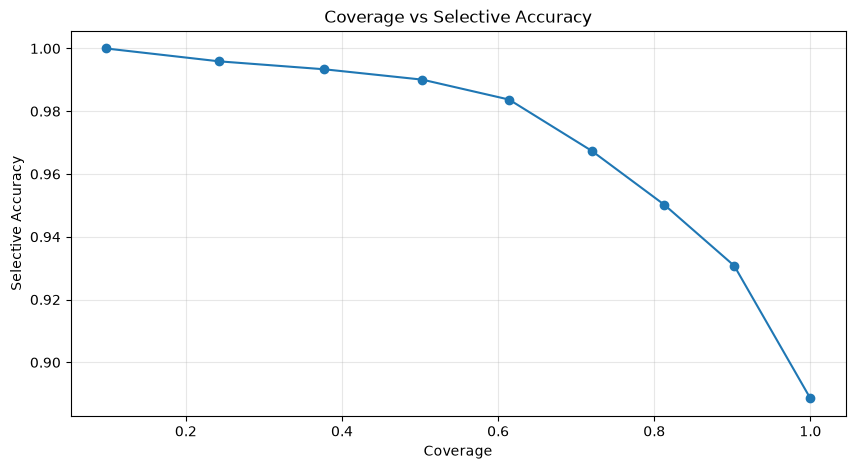

In [94]:
plt.figure(figsize=(10, 5))
plt.plot(
    threshold_df["coverage"],
    threshold_df["selective_accuracy"],
    marker="o",
)
plt.xlabel("Coverage")
plt.ylabel("Selective Accuracy")
plt.title("Coverage vs Selective Accuracy")
plt.grid(alpha=0.3)
plt.show()


**Observed trade-off:** At a `0.4` threshold, Coverage was **0.7200**, Selective Accuracy was **0.9674**, and **47** mistakes were automatically accepted. At `0.5`, Selective Accuracy improved to **0.9837** but Coverage dropped to **0.6140**. Choosing a threshold requires product and risk criteria, not just maximization of accepted accuracy.

## 7. Probability Calibration & Routing Policy Comparison

### 7.1 Top-label calibration and Expected Calibration Error

Calibration asks whether prediction confidence tracks observed correctness. Group validation examples into confidence bins and compare their mean confidence with observed accuracy. This is a **top-label** calibration diagnostic; it does not establish calibration for every individual intent.

In [95]:
confidence_bins = np.linspace(0, 1, 11)

calibration_df = (
    confidence_df
    .assign(confidence_bin=pd.cut(
        confidence_df["confidence"],
        bins=confidence_bins,
        include_lowest=True,
    ))
    .groupby("confidence_bin", observed=True)
    .agg(
        sample_count=("correct", "size"),
        mean_confidence=("confidence", "mean"),
        actual_accuracy=("correct", "mean"),
    )
    .reset_index()
)
display(calibration_df)


,confidence_bin,sample_count,mean_confidence,actual_accuracy
0,"(-0.001, 0.1]",55,0.075471,0.345455
1,"(0.1, 0.2]",140,0.153531,0.557143
2,"(0.2, 0.3]",179,0.254734,0.754190
3,"(0.3, 0.4]",186,0.352207,0.817204
4,"(0.4, 0.5]",212,0.450970,0.872642
5,"(0.5, 0.6]",222,0.549957,0.954955
6,"(0.6, 0.7]",252,0.651844,0.980159
7,"(0.7, 0.8]",268,0.748986,0.988806
8,"(0.8, 0.9]",291,0.853868,0.993127
9,"(0.9, 1.0]",195,0.935815,1.000000


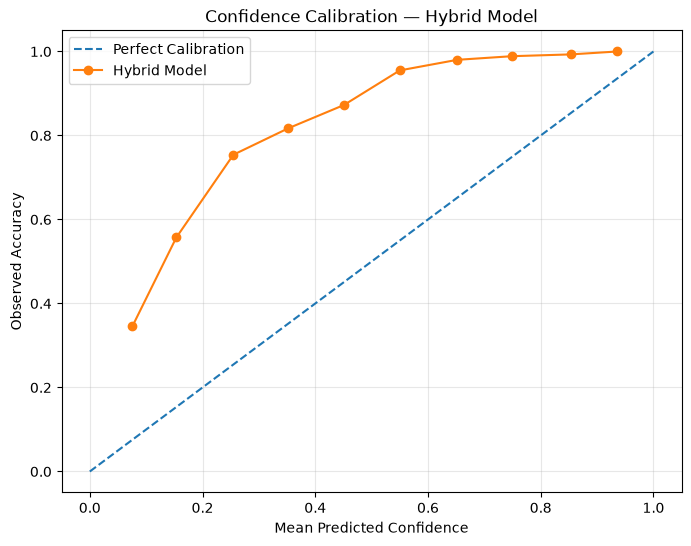

In [96]:
plt.figure(figsize=(8, 6))
plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect Calibration")
plt.plot(
    calibration_df["mean_confidence"],
    calibration_df["actual_accuracy"],
    marker="o",
    label="Hybrid Model",
)
plt.xlabel("Mean Predicted Confidence")
plt.ylabel("Observed Accuracy")
plt.title("Confidence Calibration — Hybrid Model")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [97]:
calibration_df["calibration_gap"] = (
    calibration_df["actual_accuracy"] - calibration_df["mean_confidence"]
)

original_ece = (
    calibration_df["sample_count"]
    * calibration_df["calibration_gap"].abs()
).sum() / calibration_df["sample_count"].sum()

print(f"Expected Calibration Error: {original_ece:.4f}")


Expected Calibration Error: 0.3133


**Observation:** The original Hybrid model's 10-bin top-label ECE was **0.3133**. Observed accuracy exceeded mean confidence in every displayed bin, consistent with substantial **underconfidence** on this validation set. ECE depends on the binning scheme and must not be interpreted as a universal model-quality score.

### 7.2 Experiment 05 — Sigmoid probability calibration

Fit sigmoid calibration using **cross-validation within the training portion only** (`cv=3`, `ensemble=False`). Do not fit the calibrator using the validation set or the held-out test set. Calibration is intended to improve probability reliability; in multiclass settings it may also change the top predicted label.

In [98]:
calibrated_model = CalibratedClassifierCV(
    estimator=clone(hybrid_model),
    method="sigmoid",
    cv=3,
    ensemble=False,
)
calibrated_model.fit(X_train, y_train)


,"estimator estimator: estimator instance, default=NoneThe classifier whose output need to be calibrated to provide moreaccurate `predict_proba` outputs. The default classifier isa :class:`~sklearn.svm.LinearSVC`... versionadded:: 1.2",Pipeline(step..._iter=1000))])
,"cv cv: int, cross-validation generator, or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- integer, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. If ``y`` isneither binary nor multiclass, :class:`~sklearn.model_selection.KFold`is used.Refer to the :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"ensemble ensemble: bool, or ""auto"", default=""auto""Determines how the calibrator is fitted.""auto"" will use `False` if the `estimator` is a:class:`~sklearn.frozen.FrozenEstimator`, and `True` otherwise.If `True`, the `estimator` is fitted using training data, andcalibrated using testing data, for each `cv` fold. The final estimatoris an ensemble of `n_cv` fitted classifier and calibrator pairs, where`n_cv` is the number of cross-validation folds. The output is theaverage predicted probabilities of all pairs.If `False`, `cv` is used to compute unbiased predictions, via:func:`~sklearn.model_selection.cross_val_predict`, which are thenused for calibration. At prediction time, the classifier used is the`estimator` trained on all the data.Note that this method is also internally implemented in:mod:`sklearn.svm` estimators with the `probabilities=True` parameter... versionadded:: 0.24.. versionchanged:: 1.6 `""auto""` option is added and is the default.",False
,"method method: {'sigmoid', 'isotonic', 'temperature'}, default='sigmoid'The method to use for calibration. Can be:- 'sigmoid', which corresponds to Platt's method (i.e. a binary logistic regression model).- 'isotonic', which is a non-parametric approach.- 'temperature', temperature scaling.Sigmoid and isotonic calibration methods natively support only binaryclassifiers and extend to multi-class classification using a One-vs-Rest (OvR)strategy with post-hoc renormalization, i.e., adjusting the probabilities aftercalibration to ensure they sum up to 1.In contrast, temperature scaling naturally supports multi-class calibration byapplying `softmax(classifier_logits/T)` with a value of `T` (temperature)that optimizes the log loss.For very uncalibrated classifiers on very imbalanced datasets, sigmoidcalibration might be preferred because it fits an additional interceptparameter. This helps shift decision boundaries appropriately when theclassifier being calibrated is biased towards the majority class.Isotonic calibration is not recommended when the number of calibration samplesis too low ``(≪1000)`` since it then tends to overfit... versionchanged:: 1.8 Added option 'temperature'.",'sigmoid'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors.Base estimator clones are fitted in parallel across cross-validationiterations.See :term:`Glossary <n_jobs>` for more details... versionadded:: 0.24",None
Name,Type,Value
"calibrated_classifiers_ calibrated_classifiers_: list (len() equal to cv or 1 if `ensemble=False`)The list of classifier and calibrator pairs.- When `ensemble=True`, `n_cv` fitted `estimator` and calibrator pairs. `n_cv` is the number of cross-validation folds.- When `ensemble=False`, the `estimator`, fitted on all the data, and fitted calibrator... versionchanged:: 0.24 Single calibrated classifier case when `ensemble=False`.",list,[<sklearn.cali...t 0x11c5fee90>]
"clas

In [99]:
val_pred_calibrated = calibrated_model.predict(X_val)
val_calibrated_proba = calibrated_model.predict_proba(X_val)
val_calibrated_confidence = val_calibrated_proba.max(axis=1)

calibrated_df = pd.DataFrame({
    "confidence": val_calibrated_confidence,
    "correct": val_pred_calibrated == y_val.to_numpy(),
})


In [100]:
calibrated_df["bin"] = pd.cut(
    calibrated_df["confidence"],
    bins=confidence_bins,
    include_lowest=True,
)

calibration_results = (
    calibrated_df.groupby("bin", observed=True)
    .agg(
        count=("correct", "size"),
        mean_confidence=("confidence", "mean"),
        accuracy=("correct", "mean"),
    )
)

calibrated_ece = (
    calibration_results["count"]
    * (calibration_results["accuracy"] - calibration_results["mean_confidence"]).abs()
).sum() / len(calibrated_df)

print("Original ECE:", round(original_ece, 4))
print("Calibrated ECE:", round(calibrated_ece, 4))
print("Calibrated Accuracy:", accuracy_score(y_val, val_pred_calibrated))
print("Calibrated Macro F1:", f1_score(y_val, val_pred_calibrated, average="macro"))

display(calibration_results)


Original ECE: 0.3133
Calibrated ECE: 0.2123
Calibrated Accuracy: 0.8835
Calibrated Macro F1: 0.8842240053366223


,count,mean_confidence,accuracy
bin,,,
"(-0.001, 0.1]",1,0.093207,0.000000
"(0.1, 0.2]",20,0.161306,0.200000
"(0.2, 0.3]",52,0.261777,0.480769
"(0.3, 0.4]",131,0.355532,0.648855
"(0.4, 0.5]",249,0.455263,0.742972
"(0.5, 0.6]",282,0.548348,0.858156
"(0.6, 0.7]",272,0.654458,0.937500
"(0.7, 0.8]",314,0.752142,0.961783
"(0.8, 0.9]",425,0.848718,0.976471


**Findings — Probability calibration:** ECE decreased from **0.3133 → 0.2123** (about 32.2% relative reduction), while Accuracy decreased from **0.8885 → 0.8835** and Macro F1 from **0.8890 → 0.8842**. Thus, probability calibration improved but remained imperfect; the calibrated estimator did not win on classification performance.

### 7.3 Experiment 06 — Same threshold, different coverage

Apply the original candidate threshold `0.4` to both estimators. This reveals how probability calibration changes the simulated automation decision at a fixed numerical score threshold; it is **not** a like-for-like coverage comparison.

In [101]:
routing_threshold = 0.4
routing_models = {
    "Original Hybrid": confidence_df,
    "Calibrated Hybrid": calibrated_df,
}

fixed_threshold_rows = []
for name, frame in routing_models.items():
    accepted_mask = frame["confidence"] >= routing_threshold
    coverage = accepted_mask.mean()

    fixed_threshold_rows.append({
        "Model": name,
        "Coverage": coverage,
        "Fallback Rate": 1 - coverage,
        "Selective Accuracy": frame.loc[accepted_mask, "correct"].mean(),
        "Accepted Errors": (accepted_mask & ~frame["correct"]).sum(),
    })

fixed_threshold_df = pd.DataFrame(fixed_threshold_rows)
display(fixed_threshold_df.round(4))


,Model,Coverage,Fallback Rate,Selective Accuracy,Accepted Errors
0,Original Hybrid,0.720,0.280,0.9674,47
1,Calibrated Hybrid,0.898,0.102,0.9204,143


**Finding — Fixed threshold:** At threshold `0.4`, calibrated Coverage rose **0.720 → 0.898**, while accepted errors rose **47 → 143** and Selective Accuracy fell **0.9674 → 0.9204**. The scores changed scale; this comparison alone does **not** establish calibration as worse for routing.

### 7.4 Experiment 07 — Equal coverage comparison

To compare both confidence-based routing policies at the same automation capacity, accept the **top 72% highest-confidence messages** from each model. The selected messages can differ; 72% was chosen from the earlier validation analysis, so this remains a development-set comparison.

In [102]:
target_coverage = 0.72
n_accept = round(len(confidence_df) * target_coverage)

equal_coverage_rows = []
for name, frame in routing_models.items():
    accepted_messages = frame.nlargest(n_accept, "confidence")
    equal_coverage_rows.append({
        "Model": name,
        "Coverage": len(accepted_messages) / len(frame),
        "Selective Accuracy": accepted_messages["correct"].mean(),
        "Accepted Errors": (~accepted_messages["correct"]).sum(),
        "Min Accepted Confidence": accepted_messages["confidence"].min(),
    })

equal_coverage_df = pd.DataFrame(equal_coverage_rows)
display(equal_coverage_df.round(4))


,Model,Coverage,Selective Accuracy,Accepted Errors,Min Accepted Confidence
0,Original Hybrid,0.72,0.9674,47,0.4012
1,Calibrated Hybrid,0.72,0.9576,61,0.5365


**Finding — Equal coverage:** At **72% Coverage**, the Original Hybrid model achieved **0.9674** Selective Accuracy with **47** errors; the calibrated version achieved **0.9576** with **61** errors. Given stronger overall metrics and 14 fewer accepted errors at equal coverage, the **Original Hybrid** remained our selected model for final hold-out evaluation. These findings are based on a single validation set.

## 8. Train/Test Overlap Audit & Final Hold-out Evaluation

### 8.1 Audit benchmark overlap before testing

Even when using a published train/test split, normalized duplicates can undermine the independence of test observations. Inspect any overlaps, compare their labels, and exclude overlapping test rows **without altering model parameters or retuning the threshold**. This changes the benchmark sample size, so report the difference explicitly.

In [103]:
# Load the official test file only after model and routing decisions are fixed.
test = pd.read_csv(data_dir / "test.csv")

train_overlap_audit = train[["text", "category"]].copy()
train_overlap_audit["normalized"] = normalize_text(train_overlap_audit["text"])
test["normalized"] = normalize_text(test["text"])

overlap = test.loc[
    test["normalized"].isin(train_overlap_audit["normalized"])
].copy()

print("Overlapping test records:", len(overlap))
display(overlap)


Overlapping test records: 7


,text,category,normalized
554,How do I unblock my PIN?,pin_blocked,how do i unblock my pin?
976,\n\nWhat businesses accept this card?,card_acceptance,what businesses accept this card?
977,Where can I use my card?,card_acceptance,where can i use my card?
1432,"There are a few transaction that I don't recognize, I think someone managed to get my card details and use it.",compromised_card,"there are a few transaction that i don't recognize, i think someone managed to get my card details and use it."
1474,At which ATMs can I use this card?,atm_support,at which atms can i use this card?
2149,Which cash machines will allow me to change my PIN?,change_pin,which cash machines will allow me to change my pin?
3070,I don't live in the UK. Can I still get a card?,country_support,i don't live in the uk. can i still get a card?


In [104]:
# Check whether duplicated test/train utterances also have inconsistent labels.
overlap_comparison = overlap.merge(
    train_overlap_audit[["normalized", "category"]],
    on="normalized",
    suffixes=("_test", "_train"),
)

display(overlap_comparison[["text", "category_test", "category_train"]])


,text,category_test,category_train
0,How do I unblock my PIN?,pin_blocked,pin_blocked
1,\n\nWhat businesses accept this card?,card_acceptance,card_acceptance
2,Where can I use my card?,card_acceptance,card_acceptance
3,"There are a few transaction that I don't recognize, I think someone managed to get my card details and use it.",compromised_card,compromised_card
4,At which ATMs can I use this card?,atm_support,atm_support
5,Which cash machines will allow me to change my PIN?,change_pin,change_pin
6,I don't live in the UK. Can I still get a card?,country_support,country_support


**Audit finding:** Seven test utterances matched normalized training utterances; all seven had matching labels. Since the selected model was trained on only 80% of the cleaned training data, some overlaps might have appeared in validation rather than training. Excluding all seven test rows is a conservative independence rule. **Final test size: 3,073 instead of the original 3,080**.

### 8.2 Final unseen test classification metrics

Use the existing, fitted `hybrid_model` and the fixed model settings. Do **not** call `.fit()` again or change parameters based on the results. Compare test performance with the development-set metrics, and inspect critical intents separately.

In [105]:
test_clean = test.loc[
    ~test["normalized"].isin(train_overlap_audit["normalized"])
].copy()

X_test = test_clean["text"]
y_test = test_clean["category"]

print("Original test size:", len(test))
print("Clean test size:", len(test_clean))


Original test size: 3080
Clean test size: 3073


In [106]:
# Final test: predictions from the already trained Original Hybrid model.
test_pred_hybrid = hybrid_model.predict(X_test)
test_accuracy = accuracy_score(y_test, test_pred_hybrid)
test_macro_f1 = f1_score(y_test, test_pred_hybrid, average="macro")

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Macro F1: {test_macro_f1:.4f}")


Test Accuracy: 0.8936
Test Macro F1: 0.8936


In [107]:
report_test_df = pd.DataFrame(
    classification_report(
        y_test,
        test_pred_hybrid,
        output_dict=True,
        zero_division=0,
    )
).T

critical_intents = [
    "lost_or_stolen_card",
    "virtual_card_not_working",
    "card_acceptance",
]

display(
    report_test_df.loc[
        critical_intents,
        ["precision", "recall", "f1-score", "support"],
    ].round(4)
)


,precision,recall,f1-score,support
lost_or_stolen_card,0.8750,0.8750,0.8750,40.0
virtual_card_not_working,1.0000,0.5750,0.7302,40.0
card_acceptance,0.9429,0.8684,0.9041,38.0


### 8.3 Final simulated routing metrics at threshold 0.4

Keep the validation-selected threshold fixed. `Coverage` is the fraction of **test utterances** accepted by the classifier; `Selective Accuracy` is the fraction correctly labeled **among accepted utterances**. These are not proof of successfully resolved customer journeys.

In [108]:
test_proba = hybrid_model.predict_proba(X_test)
test_confidence = test_proba.max(axis=1)
test_accepted_mask = test_confidence >= 0.4
test_correct_mask = test_pred_hybrid == y_test.to_numpy()

coverage = test_accepted_mask.mean()
selective_accuracy = test_correct_mask[test_accepted_mask].mean()
accepted_errors = np.sum(test_accepted_mask & ~test_correct_mask)

print(f"Coverage: {coverage:.4f}")
print(f"Fallback Rate: {1 - coverage:.4f}")
print(f"Selective Accuracy: {selective_accuracy:.4f}")
print(f"Accepted Errors: {accepted_errors}")


Coverage: 0.7205
Fallback Rate: 0.2795
Selective Accuracy: 0.9643
Accepted Errors: 79


## 9. Final Findings & Next Steps

### Held-out results (original run)

| Measure | Validation (2,000 utterances) | Hold-out test (3,073 utterances) |
|---|---:|---:|
| Accuracy | 0.8885 | **0.8936** |
| Macro F1 | 0.8890 | **0.8936** |
| Coverage at fixed 0.4 threshold | 0.7200 | **0.7205** |
| Simulated Fallback Rate | 0.2800 | **0.2795** |
| Selective Accuracy | 0.9674 | **0.9643** |
| Accepted misclassifications | 47 | **79** |

**Critical-intent test Recall:** `lost_or_stolen_card` **0.8750** (35/40), `virtual_card_not_working` **0.5750** (23/40), and `card_acceptance` **0.8684** (33/38).

### Conclusions

1. Combining word and character TF-IDF features improved aggregate intent classification relative to the tested word-only baseline.
2. Intent-level errors remain material, especially for virtual-card functionality and security-relevant card events.
3. Higher selective accuracy can be achieved by abstaining on low-confidence predictions, at the cost of reduced automatic coverage.
4. Sigmoid calibration reduced top-label ECE but did not improve equal-coverage selective accuracy in this development experiment.
5. The reported test evaluation excluded **seven** overlapping train/test utterances and was not used for further tuning.

### Limitations and responsible interpretation

- The study uses **isolated, labeled customer utterances** rather than full conversations or live banking operations.
- The validation set was reused for several experiments; selection effects and limited examples per class mean exact performance gains are uncertain.
- Some original labels appear ambiguous or potentially inconsistent; we **flagged**, but did not silently rewrite, these labels.
- `predict_proba` scores are not necessarily calibrated probabilities. The candidate `0.4` threshold is an **offline routing simulation**, not a bank-approved production decision rule.
- Successful classification does **not** imply that a customer request was resolved, nor that a security-critical action should be automated without validation.

### Handoff to Notebook 03 — Customer Dialogue Analytics & SQL

Next, separately design **synthetic** `conversations`, `conversation_turns`, and `action_events` tables to simulate session-level journeys and measure resolution, handoff, and action-success metrics. Label simulated records clearly; BANKING77 alone cannot supply those real-world outcomes.